In [98]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [99]:
df = pd.read_csv("taxi_trip_pricing.csv")


In [100]:
df = df.dropna(subset=["Trip_Price"]).copy()


In [101]:
numeric_cols = df.select_dtypes(include=["number"]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical features with their most common value
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])



In [102]:
X = df.drop("Trip_Price", axis=1)
y = df["Trip_Price"]


In [103]:
X = pd.get_dummies(X, drop_first=True, dtype=int)


In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [105]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [106]:
poly = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)



In [107]:
poly_scaler = StandardScaler()

X_train_poly = poly_scaler.fit_transform(X_train_poly)
X_test_poly = poly_scaler.transform(X_test_poly)


In [108]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

In [116]:
sgd_model = SGDRegressor(
    loss="squared_error",
    learning_rate="constant",
    eta0=0.00001,
    max_iter=2000,
    tol=1e-4,
    random_state=42
)

sgd_model.fit(X_train_poly, y_train_scaled)

sgd_predictions_scaled = sgd_model.predict(X_test_poly)

sgd_predictions = y_scaler.inverse_transform(
    sgd_predictions_scaled.reshape(-1, 1)
).ravel()

In [136]:

# Train SGD with Momentum again
# Prepare the cubic polynomial features for Momentum
X_train_momentum = np.column_stack(
    (np.ones(len(X_train_poly)), X_train_poly)
)

X_test_momentum = np.column_stack(
    (np.ones(len(X_test_poly)), X_test_poly)
)

weights = np.zeros(X_train_momentum.shape[1])
velocity = np.zeros_like(weights)

learning_rate = 0.0001
momentum = 0.9
epochs = 100
batch_size = 32

for epoch in range(epochs):

    indices = np.random.permutation(len(y_train_scaled))

    for start in range(0, len(indices), batch_size):

        batch = indices[start:start + batch_size]

        X_batch = X_train_momentum[batch]
        y_batch = y_train_scaled[batch]

        # Calculate predictions
        predictions = X_batch @ weights

        # Calculate the average gradient
        gradient = X_batch.T @ (predictions - y_batch) / len(batch)

        # Standard momentum update
        velocity = momentum * velocity + learning_rate * gradient
        weights = weights - velocity

# Predict prices again
momentum_predictions_scaled = X_test_momentum @ weights

momentum_predictions = y_scaler.inverse_transform(
    momentum_predictions_scaled.reshape(-1, 1)
).ravel()

# Evaluate again
print("MSE:", mean_squared_error(y_test, momentum_predictions))
print("R2 Score:", r2_score(y_test, momentum_predictions))


MSE: 513.028015103676
R2 Score: 0.7805113989091068


In [137]:
print("SGD Results")
print("MSE:", mean_squared_error(y_test, sgd_predictions))
print("R2 Score:", r2_score(y_test, sgd_predictions))

print("\nSGD with Momentum Results")
print("MSE:", mean_squared_error(y_test, momentum_predictions))
print("R2 Score:", r2_score(y_test, momentum_predictions))

SGD Results
MSE: 543.724397474406
R2 Score: 0.7673785760870604

SGD with Momentum Results
MSE: 513.028015103676
R2 Score: 0.7805113989091068


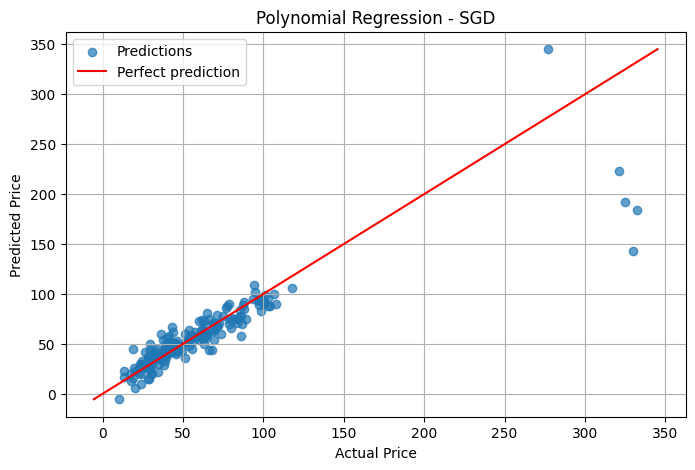

In [138]:
import matplotlib.pyplot as plt

# ==========================================
# CHART 1: SGD - Actual vs Predicted Prices
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(y_test, sgd_predictions, alpha=0.7, label="Predictions")

# Perfect prediction line
minimum = min(y_test.min(), sgd_predictions.min())
maximum = max(y_test.max(), sgd_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Polynomial Regression - SGD")
plt.legend()
plt.grid(True)
plt.show()


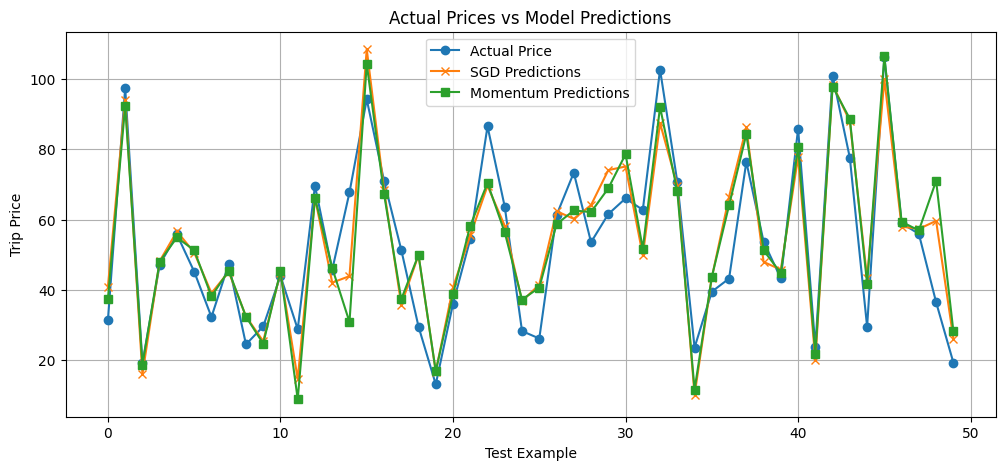

In [139]:
# Show the first 50 test examples
plt.figure(figsize=(12, 5))

plt.plot(
    np.array(y_test)[:50],
    marker="o",
    label="Actual Price"
)

plt.plot(
    sgd_predictions[:50],
    marker="x",
    label="SGD Predictions"
)

plt.plot(
    momentum_predictions[:50],
    marker="s",
    label="Momentum Predictions"
)

plt.xlabel("Test Example")
plt.ylabel("Trip Price")
plt.title("Actual Prices vs Model Predictions")
plt.legend()
plt.grid(True)
plt.show()

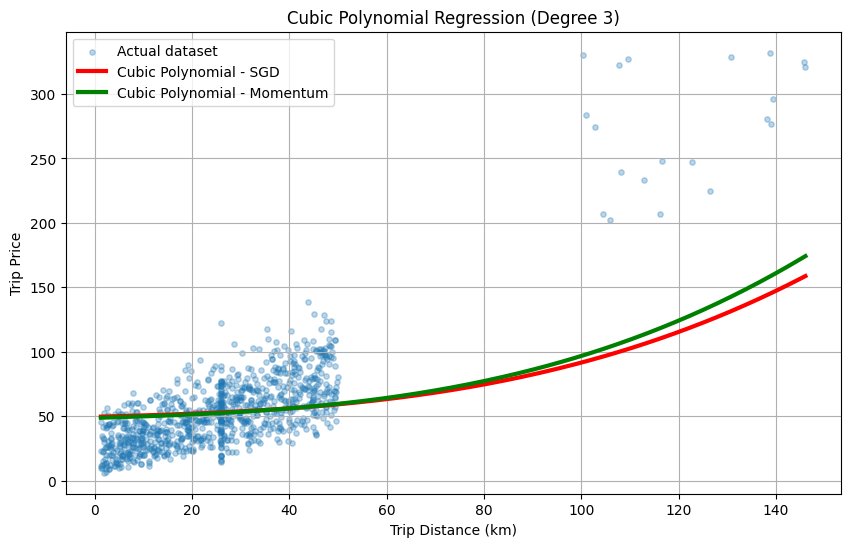

In [140]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Choose one feature for the x-axis
feature = "Trip_Distance_km"

# Create evenly spaced distances for a smooth curve
x_curve = np.linspace(
    X[feature].min(),
    X[feature].max(),
    200
)

# Start with all features at their average values
X_curve = pd.DataFrame(
    [X.mean(numeric_only=True).to_dict()] * len(x_curve)
)

# Keep the same columns and vary only trip distance
X_curve[feature] = x_curve
X_curve = X_curve[X.columns]

# Apply the same preprocessing used during training
X_curve_scaled = scaler.transform(X_curve)
X_curve_poly = poly.transform(X_curve_scaled)
X_curve_poly = poly_scaler.transform(X_curve_poly)

# Predict with SGD
y_sgd_curve = y_scaler.inverse_transform(
    sgd_model.predict(X_curve_poly).reshape(-1, 1)
).ravel()

# Predict with Momentum
X_curve_momentum = np.column_stack(
    (np.ones(len(X_curve_poly)), X_curve_poly)
)

# Check that momentum weights match the cubic features
if X_curve_momentum.shape[1] != len(weights):
    raise ValueError(
        "Retrain the momentum model using degree=3 before plotting."
    )

y_momentum_curve = y_scaler.inverse_transform(
    (X_curve_momentum @ weights).reshape(-1, 1)
).ravel()

# Plot the original dataset and both curves
plt.figure(figsize=(10, 6))

plt.scatter(
    X[feature], y,
    alpha=0.3,
    s=15,
    label="Actual dataset"
)

plt.plot(
    x_curve, y_sgd_curve,
    color="red",
    linewidth=3,
    label="Cubic Polynomial - SGD"
)

plt.plot(
    x_curve, y_momentum_curve,
    color="green",
    linewidth=3,
    label="Cubic Polynomial - Momentum"
)

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Price")
plt.title("Cubic Polynomial Regression (Degree 3)")
plt.legend()
plt.grid(True)
plt.show()


In [142]:

from sklearn.metrics import mean_squared_error, r2_score

# Calculate the results for SGD
sgd_mse = mean_squared_error(y_test, sgd_predictions)
sgd_r2 = r2_score(y_test, sgd_predictions)

# Calculate the results for SGD with Momentum
momentum_mse = mean_squared_error(y_test, momentum_predictions)
momentum_r2 = r2_score(y_test, momentum_predictions)

# Display the results
print("===== SGD RESULTS =====")
print("MSE:", round(sgd_mse, 2))
print("R2 Score:", round(sgd_r2, 4))

print("\n===== SGD WITH MOMENTUM RESULTS =====")
print("MSE:", round(momentum_mse, 2))
print("R2 Score:", round(momentum_r2, 4))

# Compare the models
print("\n===== COMPARISON =====")

if sgd_mse < momentum_mse:
    print("SGD has lower MSE.")
else:
    print("SGD with Momentum has lower MSE.")

if sgd_r2 > momentum_r2:
    print("SGD has higher R2.")
else:
    print("SGD with Momentum has higher R2.")


===== SGD RESULTS =====
MSE: 543.72
R2 Score: 0.7674

===== SGD WITH MOMENTUM RESULTS =====
MSE: 513.03
R2 Score: 0.7805

===== COMPARISON =====
SGD with Momentum has lower MSE.
SGD with Momentum has higher R2.
